<a href="https://colab.research.google.com/github/gizemnurbektas/BERT-ROBERTA/blob/main/BERTautomaticticketclassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np, tensorflow as tf, gc
tf.keras.backend.clear_session(); gc.collect()

0

In [ ]:
!pip uninstall -y transformers accelerate huggingface-hub
!pip install -U "transformers==4.44.2" "accelerate>=0.33.0" "huggingface-hub>=0.24.0" "datasets>=2.20.0"



Found existing installation: transformers 4.44.2
Uninstalling transformers-4.44.2:
  Successfully uninstalled transformers-4.44.2
Found existing installation: accelerate 1.10.1
Uninstalling accelerate-1.10.1:
  Successfully uninstalled accelerate-1.10.1
Found existing installation: huggingface-hub 0.34.4
Uninstalling huggingface-hub-0.34.4:
  Successfully uninstalled huggingface-hub-0.34.4
  Using cached transformers-4.44.2-py3-none-any.whl.metadata (43 kB)
  Using cached accelerate-1.10.1-py3-none-any.whl.metadata (19 kB)
  Using cached huggingface_hub-0.34.4-py3-none-any.whl.metadata (14 kB)
Using cached transformers-4.44.2-py3-none-any.whl (9.5 MB)
Using cached accelerate-1.10.1-py3-none-any.whl (374 kB)
Using cached huggingface_hub-0.34.4-py3-none-any.whl (561 kB)


In [ ]:
import pandas as pd
import numpy as np, tensorflow as tf, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification, create_optimizer
import torch
from transformers import BertTokenizer, BertForSequenceClassification
from transformers import Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
from datasets import Dataset



In [ ]:
from google.colab import files
uploaded = files.upload()

Saving filtered_complaints.json to filtered_complaints.json


In [ ]:
df=pd.read_json("filtered_complaints.json")
df.head()

,complaint_what_happened,product,sub_product
0,,Debt collection,Credit card debt
1,Good morning my name is XXXX XXXX and I apprec...,Debt collection,Credit card debt
2,I upgraded my XXXX XXXX card in XX/XX/2018 and...,Credit card or prepaid card,General-purpose credit card or charge card
3,,Mortgage,Conventional home mortgage
4,,Credit card or prepaid card,General-purpose credit card or charge card


In [ ]:
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

TEXT_COL = "complaint_what_happened"
TARGET_COL = "product"
model_name = "bert-base-uncased"

MAX_LEN = 128       # bellek sorunu yaşamamak için 128 seçtik
batch_size = 8     # GPU belleğine göre ayarlanabilir (16, 8, 4, 2)
epochs = 15
init_lr = 2e-5
weight_decay = 0.01
warmup_ratio = 0.1


In [ ]:
# Gerekli kolonlar ve temizlik
df = df.dropna(subset=[TEXT_COL, TARGET_COL]).copy()
df[TARGET_COL] = df[TARGET_COL].astype(str)
df[TEXT_COL]   = df[TEXT_COL].astype(str)

In [ ]:
# Etiket haritaları
labels   = sorted(df[TARGET_COL].unique())
label2id = {l:i for i,l in enumerate(labels)}
id2label = {i:l for l,i in label2id.items()}

y_all = df[TARGET_COL].map(label2id).values.astype("int32")
X_all = df[TEXT_COL].values

In [ ]:
# Train/Val/Test: %70 / %15 / %15 (stratify)
X_tr_full, X_te, y_tr_full, y_te = train_test_split(
    X_all, y_all, test_size=0.15, random_state=SEED, stratify=y_all
)
val_ratio_within_train = 0.15 / (1 - 0.15)  # ~0.1765
X_tr, X_va, y_tr, y_va = train_test_split(
    X_tr_full, y_tr_full,
    test_size=val_ratio_within_train,
    random_state=SEED, stratify=y_tr_full
)
print(f"Split -> TRAIN:{len(y_tr)}  VAL:{len(y_va)}  TEST:{len(y_te)}  | Sınıf sayısı:{len(labels)}")


Split -> TRAIN:54819  VAL:11747  TEST:11747  | Sınıf sayısı:17


In [ ]:
# 2) TOKENIZER + ENCODE
# ==========================
tokenizer = AutoTokenizer.from_pretrained(model_name)

def encode(texts):
    enc = tokenizer(
        list(texts),
        truncation=True,
        padding="max_length",
        max_length=MAX_LEN,
        return_tensors="tf"
    )
    # DistilBERT token_type_ids üretmez; BERT için de tutarlılık sağla:
    if "token_type_ids" not in enc:
        enc["token_type_ids"] = tf.zeros_like(enc["input_ids"])
    # dtype tutarlılığı
    for k in ["input_ids", "attention_mask", "token_type_ids"]:
        enc[k] = tf.cast(enc[k], tf.int32)
    return enc

tr_enc = encode(X_tr)
va_enc = encode(X_va)
te_enc = encode(X_te)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [ ]:
# 3) TF.DATA DATASET
# ==========================
def make_ds(enc, y, bs, shuffle=False):
    y = np.asarray(y).astype("int32").reshape(-1)  # (N,) garanti
    inputs = {
        "input_ids": enc["input_ids"],
        "attention_mask": enc["attention_mask"],
        "token_type_ids": enc["token_type_ids"],
    }
    ds = tf.data.Dataset.from_tensor_slices((inputs, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(y), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(bs, drop_remainder=False).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(tr_enc, y_tr, batch_size, shuffle=True)
val_ds   = make_ds(va_enc, y_va, batch_size, shuffle=False)
test_ds  = make_ds(te_enc, y_te, batch_size, shuffle=False)

In [ ]:
# Cardinality
train_steps = tf.data.experimental.cardinality(train_ds).numpy()
val_steps   = tf.data.experimental.cardinality(val_ds).numpy()
if train_steps <= 0:
    train_steps = max(1, int(np.ceil(len(y_tr)/batch_size)))
if val_steps <= 0:
    print("Uyarı: val_ds boş görünüyor; validation olmadan eğitim yapılacak.")
print(f"steps_per_epoch: {train_steps} | validation_steps: {max(val_steps,0)}")


steps_per_epoch: 6853 | validation_steps: 1469


In [ ]:
# 4) CLASS WEIGHTS (ops.)
# ==========================
classes = np.unique(y_tr)
cw = compute_class_weight(class_weight="balanced", classes=classes, y=y_tr)
class_weight = {int(c): float(w) for c, w in zip(classes, cw)}
print("Class weights (train'de görünenler):", class_weight)

Class weights (train'de görünenler): {0: 0.46924433335615967, 1: 0.3792363940754474, 2: 4.472464714040957, 3: 0.44410509004593435, 4: 0.42665348753949844, 5: 24.06453028972783, 6: 1.0688256741211566, 7: 1.4389321993857784, 8: 3.07109243697479, 9: 20.154044117647057, 10: 0.20271874387524547, 11: 76.77731092436974, 12: 806.1617647058823, 13: 33.24378411158278, 14: 146.57486631016042, 15: 5.321199767035527, 16: 5.167703619909502}


In [ ]:
# 5) MODEL + OPTIMIZER
# ==========================
num_labels = len(labels)
model = TFAutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=num_labels, id2label=id2label, label2id=label2id
)

total_train_steps = int(train_steps) * epochs
warmup = int(warmup_ratio * total_train_steps)

optimizer, schedule = create_optimizer(
    init_lr=init_lr,
    num_warmup_steps=warmup,
    num_train_steps=total_train_steps,
    weight_decay_rate=weight_decay
)
optimizer.clipnorm = 1.0

model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
    jit_compile=False  # derleyici edge-case'lerini azaltır
)



model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

All PyTorch model weights were used when initializing TFBertForSequenceClassification.

Some weights or buffers of the TF 2.0 model TFBertForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# Warm-up build: input imzasını sabitle
_ = model({
    "input_ids": tr_enc["input_ids"][:1],
    "attention_mask": tr_enc["attention_mask"][:1],
    "token_type_ids": tr_enc["token_type_ids"][:1],
}, training=False)

In [ ]:
# 6) CALLBACKS
# ==========================
monitor_key = "val_loss" if val_steps > 0 else "loss"
ckpt_path = "best-val.weights.h5" if val_steps > 0 else "best.weights.h5"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=ckpt_path,
        monitor=monitor_key,
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor=monitor_key,
        patience=3,
        restore_best_weights=True
    )
]

# EĞİTİM


Neden bazen sabitlemek gerekir?

val_ds boş/0 batch olduğunda epoch sonunda “empty logs” patlar.

Bazı TF sürümlerinde tf.data cardinality=UNKNOWN döndürebiliyor; Keras adım sayısını kestiremeyince yine log üretemeyebiliyor.

.repeat() varsa (bizde yok), sonsuz dataset için adım sayısını mecburen vermek gerekir.

In [ ]:
# 7) EĞİTİM
# ==========================
fit_kwargs = dict(
    epochs=epochs,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
    steps_per_epoch=int(train_steps)
)
if val_steps > 0:
    fit_kwargs.update(dict(validation_data=val_ds, validation_steps=int(val_steps)))

history = model.fit(train_ds, **fit_kwargs)


Epoch 1/15
6853/6853 [==============================] - ETA: 0s - loss: 3.0538 - accuracy: 0.2747
Epoch 1: val_loss improved from inf to 1.91549, saving model to best-val.weights.h5


/usr/local/lib/python3.12/dist-packages/transformers/generation/tf_utils.py:465: UserWarning: `seed_generator` is deprecated and will be removed in a future version.
  warnings.warn("`seed_generator` is deprecated and will be removed in a future version.", UserWarning)


6853/6853 [==============================] - 1944s 280ms/step - loss: 3.0538 - accuracy: 0.2747 - val_loss: 1.9155 - val_accuracy: 0.4062
Epoch 2/15
6853/6853 [==============================] - ETA: 0s - loss: 3.0775 - accuracy: 0.3303
Epoch 2: val_loss did not improve from 1.91549
6853/6853 [==============================] - 1912s 279ms/step - loss: 3.0775 - accuracy: 0.3303 - val_loss: 2.0207 - val_accuracy: 0.4192
Epoch 3/15
6853/6853 [==============================] - ETA: 0s - loss: 3.0824 - accuracy: 0.3480
Epoch 3: val_loss improved from 1.91549 to 1.84108, saving model to best-val.weights.h5
6853/6853 [==============================] - 1919s 280ms/step - loss: 3.0824 - accuracy: 0.3480 - val_loss: 1.8411 - val_accuracy: 0.4313
Epoch 4/15
6853/6853 [==============================] - ETA: 0s - loss: 3.1078 - accuracy: 0.3593
Epoch 4: val_loss did not improve from 1.84108
6853/6853 [==============================] - 1908s 278ms/step - loss: 3.1078 - accuracy: 0.3593 - val_loss: 1.

In [ ]:
# 8 TEST DEĞERLENDİRME

logits = model.predict(test_ds, verbose=0).logits
y_pred = logits.argmax(axis=1)
print("Classification Report (TEST):\n",
      classification_report(y_te, y_pred, target_names=labels, digits=3))

Classification Report (TEST):
                                                                               precision    recall  f1-score   support

                                                     Bank account or service      0.573     0.091     0.157      1472
                                                 Checking or savings account      0.730     0.252     0.375      1822
                                                               Consumer Loan      0.381     0.104     0.163       154
                                                                 Credit card      0.620     0.096     0.167      1556
                                                 Credit card or prepaid card      0.711     0.363     0.481      1620
                                                            Credit reporting      0.000     0.000     0.000        29
Credit reporting, credit repair services, or other personal consumer reports      0.579     0.305     0.400       646
                        

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


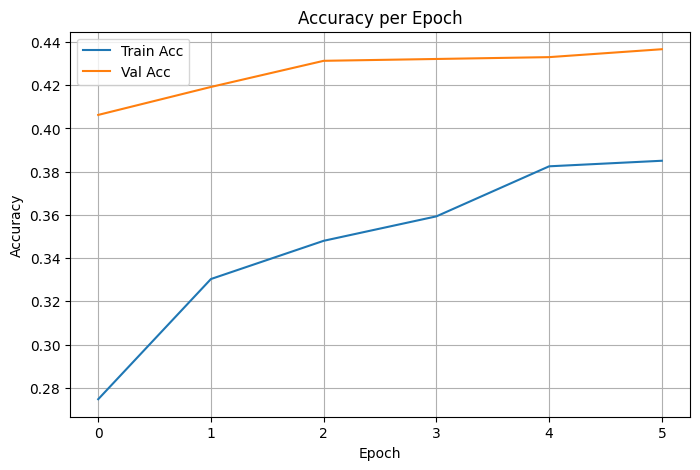

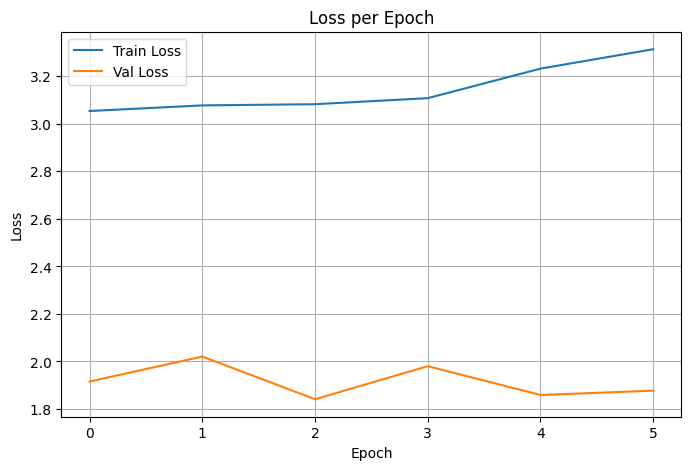

In [ ]:
# 9 GRAFİKLER
from matplotlib import pyplot as plt
if "accuracy" in history.history:
    plt.figure(figsize=(8,5))
    plt.plot(history.history["accuracy"], label="Train Acc")
    if "val_accuracy" in history.history: plt.plot(history.history["val_accuracy"], label="Val Acc")
    plt.title("Accuracy per Epoch"); plt.xlabel("Epoch"); plt.ylabel("Accuracy")
    plt.legend(); plt.grid(True); plt.show()

if "loss" in history.history:
    plt.figure(figsize=(8,5))
    plt.plot(history.history["loss"], label="Train Loss")
    if "val_loss" in history.history: plt.plot(history.history["val_loss"], label="Val Loss")
    plt.title("Loss per Epoch"); plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.legend(); plt.grid(True); plt.show()

In [ ]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

TEXT_COL   = "complaint_what_happened"
TARGET_COL = "product"
THRESH     = 1000


mask = df[TARGET_COL].notna() & df[TEXT_COL].notna()
df_use = df.loc[mask, [TEXT_COL, TARGET_COL]].copy()
df_use[TEXT_COL] = df_use[TEXT_COL].astype(str)
df_use[TARGET_COL] = df_use[TARGET_COL].astype(str)

X = df_use[TEXT_COL].to_numpy()
y = df_use[TARGET_COL].to_numpy()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

train_counts_before = pd.Series(y_tr).value_counts().sort_values(ascending=False)
test_counts_before  = pd.Series(y_te).value_counts().sort_values(ascending=False)

allowed_classes = train_counts_before[train_counts_before >= THRESH].index.tolist()
removed_classes = train_counts_before[train_counts_before < THRESH]

print("=== TRAIN sınıf sayıları (ÖNCE) ===")
print(train_counts_before)
print("\n=== TEST sınıf sayıları (ÖNCE) ===")
print(test_counts_before)

print("\n=== Eşik altı (train<%d) sınıflar ===" % THRESH)
print(removed_classes if not removed_classes.empty else "Yok")

print("\nKalacak sınıflar (>= %d): %s" % (THRESH, list(allowed_classes)))

def filter_by_allowed(X_arr, y_arr, allowed):
    keep = np.isin(y_arr, allowed)
    return X_arr[keep], y_arr[keep]

X_tr_f, y_tr_f = filter_by_allowed(X_tr, y_tr, allowed_classes)
X_te_f, y_te_f = filter_by_allowed(X_te, y_te, allowed_classes)

train_counts_after = pd.Series(y_tr_f).value_counts().sort_values(ascending=False)
test_counts_after  = pd.Series(y_te_f).value_counts().sort_values(ascending=False)

print("\n=== TRAIN (SONRA, filtrelenmiş) ===")
print(train_counts_after)
print("Toplam train önce:", len(y_tr), "→ sonra:", len(y_tr_f),
      "| Sınıf sayısı önce:", len(train_counts_before), "→ sonra:", len(train_counts_after))

print("\n=== TEST (SONRA, filtrelenmiş) ===")
print(test_counts_after)
print("Toplam test önce:", len(y_te), "→ sonra:", len(y_te_f),
      "| Sınıf sayısı önce:", len(test_counts_before), "→ sonra:", len(test_counts_after))


X_tr, y_tr, X_te, y_te = X_tr_f, y_tr_f, X_te_f, y_te_f
print("Train (filtered):", len(y_tr), " | Test (filtered):", len(y_te))




=== TRAIN sınıf sayıları (ÖNCE) ===
Mortgage                                                                        18180
Checking or savings account                                                      9717
Credit card or prepaid card                                                      8637
Credit card                                                                      8298
Bank account or service                                                          7853
Credit reporting, credit repair services, or other personal consumer reports     3448
Debt collection                                                                  2561
Money transfer, virtual currency, or money service                               1200
Consumer Loan                                                                     823
Vehicle loan or lease                                                             714
Student loan                                                                      693
Money transfers   

In [ ]:
# =========================
# 0) IMPORTS & PARAMS
# =========================
import os, gc, numpy as np, pandas as pd, tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_class_weight
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification, create_optimizer

# Stabilite & GPU ayarları
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        try: tf.config.experimental.set_memory_growth(gpu, True)
        except: pass
tf.keras.backend.clear_session(); gc.collect()

# ---- Hiperparametreler ----
# model_name = "distilbert-base-uncased"  # VRAM düşükse bunu aç
model_name = "bert-base-uncased"          # Tam BERT
MAX_LEN    = 128                           # OOM olursa 96/112 yap
BATCH_SIZE = 8                             # OOM olursa 4/2 yap
EPOCHS     = 15
INIT_LR    = 2e-5
WEIGHT_DEC = 0.01
WARMUP_R   = 0.1

# =========================
# 1) LABEL HARİTALARI
# (y_tr zaten filtreli – sadece kalan sınıflardan mapping kuruluyor)
# =========================
labels   = sorted(pd.Series(y_tr).astype(str).unique())
label2id = {l:i for i,l in enumerate(labels)}
id2label = {i:l for l,i in label2id.items()}

# String label → id
y_tr_id = np.array([label2id[s] for s in y_tr], dtype="int32")
y_te_id = np.array([label2id[s] for s in y_te], dtype="int32")

# =========================
# 2) TRAIN → VAL AYIR
# (train’in küçük bir kısmını validasyona ayırıyoruz)
# =========================
X_tr_tr, X_tr_va, y_tr_tr, y_tr_va = train_test_split(
    X_tr, y_tr_id, test_size=0.12, random_state=SEED, stratify=y_tr_id
)
# Test zaten hazır: X_te, y_te_id

# =========================
# 3) TOKENIZER & ENCODE
# =========================
tokenizer = AutoTokenizer.from_pretrained(model_name)

def encode(texts, max_len=MAX_LEN):
    enc = tokenizer(
        list(map(str, texts)),
        truncation=True, padding="max_length",
        max_length=max_len, return_tensors="tf"
    )
    # BERT/DistilBERT tutarlılığı için token_type_ids ekle
    if "token_type_ids" not in enc:
        enc["token_type_ids"] = tf.zeros_like(enc["input_ids"])
    # dtype tutarlılığı
    for k in ["input_ids", "attention_mask", "token_type_ids"]:
        enc[k] = tf.cast(enc[k], tf.int32)
    return enc

tr_enc = encode(X_tr_tr)
va_enc = encode(X_tr_va)
te_enc = encode(X_te)

# =========================
# 4) TF.DATA DATASET’LERİ
# =========================
def make_ds(enc, y, bs, shuffle=False):
    y = np.asarray(y).astype("int32").reshape(-1)  # (N,)
    inputs = {
        "input_ids": enc["input_ids"],
        "attention_mask": enc["attention_mask"],
        "token_type_ids": enc["token_type_ids"],
    }
    ds = tf.data.Dataset.from_tensor_slices((inputs, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(y), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(bs, drop_remainder=False).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(tr_enc, y_tr_tr, BATCH_SIZE, shuffle=True)
val_ds   = make_ds(va_enc, y_tr_va, BATCH_SIZE, shuffle=False)
test_ds  = make_ds(te_enc, y_te_id, BATCH_SIZE, shuffle=False)

# =========================
# 5) CLASS WEIGHT (opsiyonel, dengesiz sınıflar için)
# =========================
classes = np.unique(y_tr_tr)
cw = compute_class_weight(class_weight="balanced", classes=classes, y=y_tr_tr)
class_weight = {int(c): float(w) for c,w in zip(classes, cw)}
print("Class weights:", class_weight)

# =========================
# 6) MODEL + OPTIMIZER
# =========================
num_labels = len(labels)
model = TFAutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=num_labels, id2label=id2label, label2id=label2id
)

# Adım sayıları (yalnızca TRAIN’e göre)
train_steps = int(tf.data.experimental.cardinality(train_ds).numpy())
if train_steps <= 0:  # güvenlik
    train_steps = int(np.ceil(len(y_tr_tr)/BATCH_SIZE))
total_steps = train_steps * EPOCHS
warmup      = int(WARMUP_R * total_steps)

optimizer, schedule = create_optimizer(
    init_lr=INIT_LR,
    num_warmup_steps=warmup,
    num_train_steps=total_steps,
    weight_decay_rate=WEIGHT_DEC
)

model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
    jit_compile=False
)

# Warm-up build (input imzasını sabitle)
_ = model({
    "input_ids": tr_enc["input_ids"][:1],
    "attention_mask": tr_enc["attention_mask"][:1],
    "token_type_ids": tr_enc["token_type_ids"][:1],
}, training=False)

# =========================
# 7) CALLBACKS (EarlyStopping + Checkpoint + EpochLogger)
# =========================
from tensorflow import keras
def current_lr(opt):
    lr = opt.learning_rate
    if isinstance(lr, tf.keras.optimizers.schedules.LearningRateSchedule):
        return tf.keras.backend.get_value(lr(opt.iterations))
    return tf.keras.backend.get_value(lr)

class EpochLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        lr_val = float(current_lr(self.model.optimizer))
        logs["learning_rate"] = lr_val
        print(f"Epoch {epoch+1}: "
              f"accuracy: {logs.get('accuracy', np.nan):.4f} - "
              f"loss: {logs.get('loss', np.nan):.4f} - "
              f"val_accuracy: {logs.get('val_accuracy', np.nan):.4f} - "
              f"val_loss: {logs.get('val_loss', np.nan):.4f} - "
              f"learning_rate: {lr_val:.4e}")

monitor_key = "val_loss"
callbacks = [
    keras.callbacks.ModelCheckpoint("best-val.weights.h5",
        monitor=monitor_key, mode="min",
        save_best_only=True, save_weights_only=True, verbose=1),
    keras.callbacks.EarlyStopping(
        monitor=monitor_key, mode="min",
        patience=2, min_delta=1e-3, restore_best_weights=True, verbose=1),
    EpochLogger()
]

# =========================
# 8) EĞİTİM
# =========================
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

# =========================
# 9) TEST & RAPOR
# =========================
logits = model.predict(test_ds, verbose=0).logits
y_pred = logits.argmax(axis=1)
print("Classification Report (TEST):\n",
      classification_report(y_te_id, y_pred, target_names=labels, digits=3))

# =========================
# 10) GRAFİKLER (opsiyonel)
# =========================
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Train Acc")
plt.plot(history.history["val_accuracy"], label="Val Acc")
plt.title("Accuracy per Epoch"); plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("Loss per Epoch"); plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.legend(); plt.grid(True); plt.show()


NameError: name 'y_tr' is not defined